# Overview
> **Chuyển đổi từ `4. Training Utilities/2_Human_Gender_CNN.ipynb` sang PyTorch**
- Triển khai thực tế `ModelCheckpoint`, `EarlyStopping`, `ReduceLROnPlateau` trên vòng lặp huấn luyện thật.


In [1]:
import copy, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# (1) Data & (2) Declare Model


In [2]:
rng = np.random.default_rng(42)
x_train = rng.normal(0.45, 0.1, (600, 1, 64, 64)).astype('float32'); y_train = rng.integers(0, 2, 600, dtype=np.int64)
x_train[y_train == 1, 0, 12:48, 18:46] += 0.25; x_train = np.clip(x_train, 0, 1)
x_test = rng.normal(0.45, 0.1, (200, 1, 64, 64)).astype('float32'); y_test = rng.integers(0, 2, 200, dtype=np.int64)
x_test[y_test == 1, 0, 12:48, 18:46] += 0.25; x_test = np.clip(x_test, 0, 1)

train_loader = DataLoader(TensorDataset(torch.tensor(x_train), torch.tensor(y_train)), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.tensor(x_test), torch.tensor(y_test)), batch_size=64, shuffle=False)

class Gender_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2),
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2), nn.Dropout2d(0.2)
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(256*2*2, 256), nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, 2))
    def forward(self, x): return self.classifier(self.features(x))

model = Gender_CNN().to(device)


# (3) Training utilities (`ModelCheckpoint`, `EarlyStopping`, `ReduceLROnPlateau`) & Training


In [3]:
class EarlyStopping:
    def __init__(self, patience=3):
        self.patience, self.counter, self.best_loss, self.best_state = patience, 0, float('inf'), None
    def step(self, val_loss, model):
        if val_loss < self.best_loss - 1e-4:
            self.best_loss, self.counter, self.best_state = val_loss, 0, copy.deepcopy(model.state_dict())
            return False
        self.counter += 1
        if self.counter >= self.patience:
            model.load_state_dict(self.best_state)
            return True
        return False

class ModelCheckpoint:
    def __init__(self, path='best_gender.pt'):
        self.path, self.best_loss = Path(path), float('inf')
    def step(self, val_loss, model):
        if val_loss < self.best_loss:
            self.best_loss = val_loss
            torch.save(model.state_dict(), self.path)
            return True
        return False

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
reduce_lr = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2, min_lr=1e-5)
early_stop = EarlyStopping(patience=4)
ckpt = ModelCheckpoint('best_gender_tmp.pt')

for epoch in range(1, 15):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
    model.eval()
    val_loss, correct = 0.0, 0
    with torch.no_grad():
        for xb, yb in test_loader:
            out = model(xb.to(device))
            val_loss += criterion(out, yb.to(device)).item() * len(xb)
            correct += (out.argmax(1).cpu() == yb).sum().item()
    val_loss /= len(x_test)
    saved = ckpt.step(val_loss, model)
    reduce_lr.step(val_loss)
    print(f'Epoch {epoch:02d} | Val Loss: {val_loss:.4f} | Val Acc: {correct/len(x_test)*100:.2f}% | Saved: {saved} | LR: {optimizer.param_groups[0]["lr"]:.1e}')
    if early_stop.step(val_loss, model):
        print('EarlyStopping triggered!')
        break

model.load_state_dict(torch.load('best_gender_tmp.pt', weights_only=True))
Path('best_gender_tmp.pt').unlink(missing_ok=True)
print('Reloaded best checkpoint weights successfully!')


Epoch 01 | Val Loss: 0.6868 | Val Acc: 48.00% | Saved: True | LR: 1.0e-03


Epoch 02 | Val Loss: 0.2451 | Val Acc: 100.00% | Saved: True | LR: 1.0e-03


Epoch 03 | Val Loss: 0.0003 | Val Acc: 100.00% | Saved: True | LR: 1.0e-03


Epoch 04 | Val Loss: 0.0000 | Val Acc: 100.00% | Saved: True | LR: 1.0e-03


Epoch 05 | Val Loss: 0.0000 | Val Acc: 100.00% | Saved: True | LR: 1.0e-03


Epoch 06 | Val Loss: 0.0000 | Val Acc: 100.00% | Saved: False | LR: 1.0e-03


Epoch 07 | Val Loss: 0.0000 | Val Acc: 100.00% | Saved: False | LR: 1.0e-03


Epoch 08 | Val Loss: 0.0000 | Val Acc: 100.00% | Saved: False | LR: 1.0e-04
EarlyStopping triggered!
Reloaded best checkpoint weights successfully!


# (4) Reference Checkpoints & TensorBoard screenshots


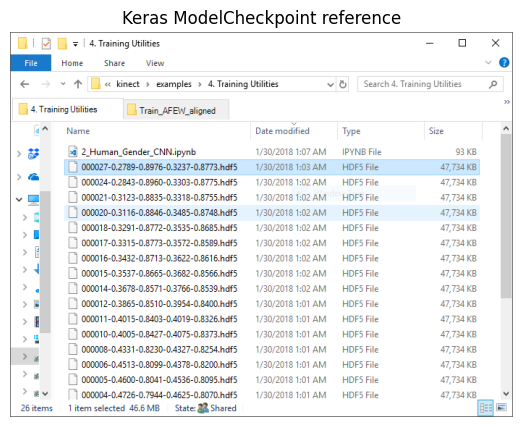

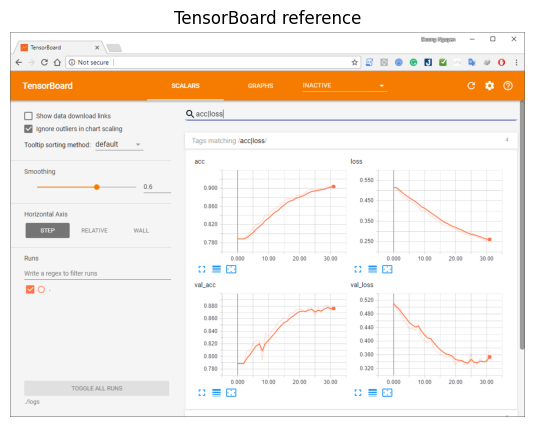

In [4]:
for img_name, title in [('checkpoints.PNG', 'Keras ModelCheckpoint reference'), ('tfboard.PNG', 'TensorBoard reference')]:
    if Path(img_name).exists():
        plt.figure(figsize=(10, 5)); plt.imshow(plt.imread(img_name)); plt.title(title); plt.axis('off'); plt.show()
